# Detection d'anomalies : apprendre le normal, signaler l'ecart

Le meme protocole pour toutes les methodes (auto-encodeur, PatchCore de la toolbox, tous les
modeles d'anomalib) : decoupage sans defaut dans train et val, seuil calibre sur des normales,
evaluation sur le test, export ONNX (image -> carte, score). Ce notebook deroule la methode de
reference (PatchCore) puis lit le banc de comparaison produit par les scripts.

In [1]:
import json  # json : affiche joliment la carte du modele a la fin
from pathlib import Path  # Path : represente un chemin de fichier, fonctionne sous Windows comme sous Linux

import matplotlib.pyplot as plt  # matplotlib : trace les figures
import numpy as np  # numpy : calcul sur des tableaux de nombres (une image = un tableau)
import pandas as pd  # pandas : tableaux de donnees (decoupage, resultats)
from IPython.display import Image, display  # affiche dans le notebook une image PNG deja enregistree sur disque

from vtb.core.config import load_config  # lit le fichier YAML de l'experience et verifie chaque reglage
from vtb.core.experiment import start  # prepare l'experience : dossier de sortie, journal, graines, choix CPU / GPU
from vtb.io.images import read_image, read_mask  # lecture d'une image et d'un masque de defaut (tableau de 0 et de 1)
from vtb.split import load_split  # relit le decoupage train / val / test enregistre dans split.csv
from vtb.tasks.anomaly import workflow  # les etapes de la recette anomalies (prepare, train, evaluate, predict, export)
from vtb.tasks.anomaly.config import AnomalyConfig  # le modele de configuration : la liste des cles autorisees dans le YAML

# charge la config de reference : PatchCore simplifie sur les bouteilles de MVTec AD (jeu public d'anomalies industrielles)
config = load_config("recipes/anomaly/configs/patchcore_lite_bottle.yaml", AnomalyConfig)
config = config.model_copy(  # copie de la config avec quelques valeurs changees (la config d'origine n'est pas modifiee)
    update={  # dict {section: nouvelle valeur de la section}
        "patchcore_lite": config.patchcore_lite.model_copy(update={"memory_fraction": 0.02}),  # plus rapide pour le notebook
        # sorties dans un dossier a part ; num_workers=0 : chargement des images dans le processus principal (sur dans un notebook)
        "runtime": config.runtime.model_copy(update={"output_dir": "outputs/anomaly/notebook", "num_workers": 0}),
    }
)
output, device = start(config, "notebook")  # cree le dossier de sortie, le journal, fixe les graines ; device = CPU ou GPU

2026-11-05 19:34:30,128 | INFO | notebook | sortie outputs/anomaly/notebook | device cpu


## 1. Les donnees : que des normales pour apprendre, des defauts pour evaluer

In [2]:
if not Path(config.split.file).exists():  # si le decoupage n'a pas encore ete fait
    workflow.prepare(config)  # catalogue des images + decoupage train / val / test (defauts tous en test)
split = load_split(config.split.file)  # relit le decoupage : une ligne par image (path, split, defect_type, mask_path...)
print(pd.crosstab(split["defect_type"], split["split"]))  # tableau croise : nombre d'images par type de defaut et par partie

split          test  train  val
defect_type                    
broken_large     20      0    0
broken_small     22      0    0
contamination    21      0    0
good             20    177   32


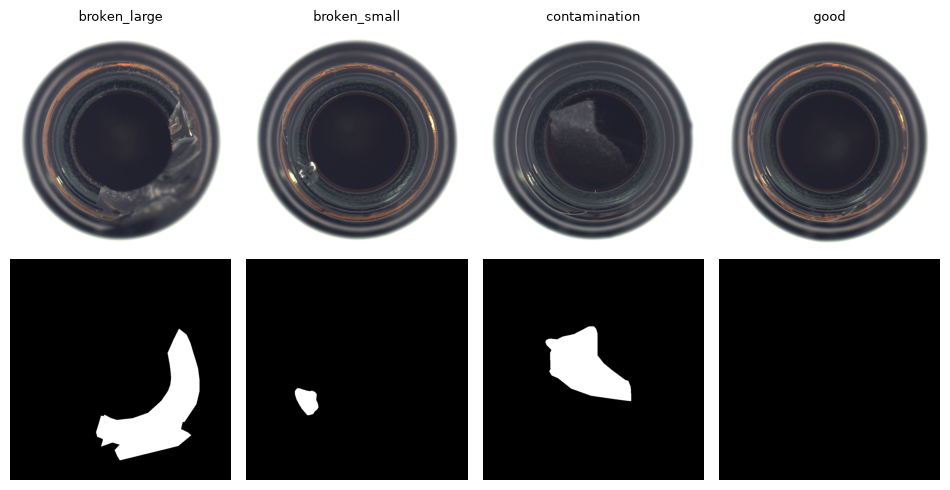

In [3]:
examples = split[split["split"] == "test"].groupby("defect_type").head(1)  # une image de test par type de defaut
fig, axes = plt.subplots(2, len(examples), figsize=(2.4 * len(examples), 5))  # grille 2 lignes (image, masque) x nb de types
for k, (_, row) in enumerate(examples.iterrows()):  # pour chaque exemple ; k = numero de colonne, row = ligne du tableau
    axes[0, k].imshow(read_image(row["path"]))  # 1re ligne : l'image
    axes[0, k].set_title(row["defect_type"], fontsize=9)  # titre : le type de defaut
    # masque du defaut (pixels a 1 la ou est le defaut) ; image vide 10 x 10 pour les pieces normales (pas de masque)
    mask = read_mask(row["mask_path"]) if row["mask_path"] else np.zeros((10, 10))
    axes[1, k].imshow(mask, cmap="gray")  # 2e ligne : le masque en noir et blanc
    for ax in axes[:, k]:  # pour les deux cases de cette colonne
        ax.axis("off")  # masque les axes gradues
plt.tight_layout()  # resserre les cases
plt.show()  # affiche la figure

## 2. Construire la memoire (pas d'entrainement) et calibrer le seuil

Le seuil est le quantile 0,99 des scores des normales de VALIDATION : on accepte 1 % de
fausses alarmes sur des pieces bonnes, sans avoir vu un seul defaut.

In [4]:
# PatchCore : garde en memoire des vecteurs de petits morceaux (patchs) d'images normales ; le score d'une
# nouvelle image = distance a ce qu'il a deja vu de plus proche. Ici : remplit la memoire puis fixe le seuil
summary = workflow.train(config, output, device)
print({k: summary[k] for k in ("fit_seconds", "image_threshold", "n_val_normals")})  # duree, seuil choisi, nb de normales de val

2026-11-05 19:35:02,852 | INFO | coreset : 0 / 3624 vecteurs choisis parmi 181248


2026-11-05 19:35:15,190 | INFO | coreset : 362 / 3624 vecteurs choisis parmi 181248


2026-11-05 19:35:28,916 | INFO | coreset : 724 / 3624 vecteurs choisis parmi 181248


2026-11-05 19:35:55,356 | INFO | coreset : 1086 / 3624 vecteurs choisis parmi 181248


2026-11-05 19:36:17,020 | INFO | coreset : 1448 / 3624 vecteurs choisis parmi 181248


2026-11-05 19:36:39,369 | INFO | coreset : 1810 / 3624 vecteurs choisis parmi 181248


... (5 outputs left out)

2026-11-05 19:39:23,660 | INFO | memoire PatchCore : 3624 vecteurs de dimension 384 (sur 181248, coreset greedy)


2026-11-05 19:39:23,677 | INFO | methode patchcore_lite : 292.6 s


2026-11-05 19:39:35,373 | INFO | seuil image 1.91532 (quantile 0.990 de 32 normales de validation) -> outputs/anomaly/notebook/model.pt


{'fit_seconds': 292.6, 'image_threshold': 1.9153181314468384, 'n_val_normals': 32}


## 3. Evaluer sur le test

2026-11-05 19:39:57,697 | INFO | scoring du test : 22.3 s


2026-11-05 19:40:00,701 | INFO | test : AUROC image 1.000 | AUROC pixel 0.982 | rappel 1.000 | fausses alarmes 0.000 | par type {'broken_large': 1.0, 'broken_small': 1.0, 'contamination': 1.0}


{'n_images': 83, 'n_defects': 63, 'auroc_image': 1.0, 'auroc_pixel': 0.982, 'recall': 1.0, 'false_alarm_rate': 0.0, 'f1': 1.0, 'recall_per_type': {'broken_large': 1.0, 'broken_small': 1.0, 'contamination': 1.0}, 'image_threshold': 1.915, 'ms_per_image': 268.4}


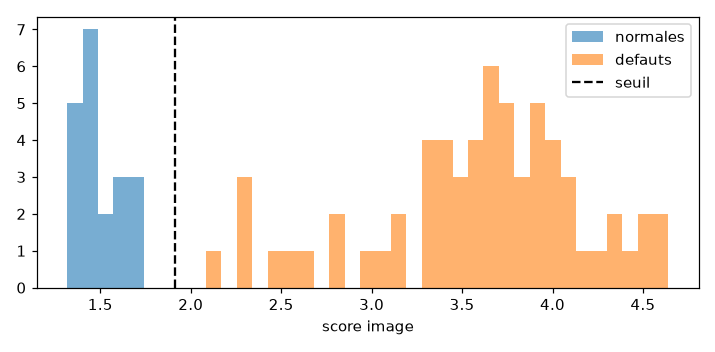

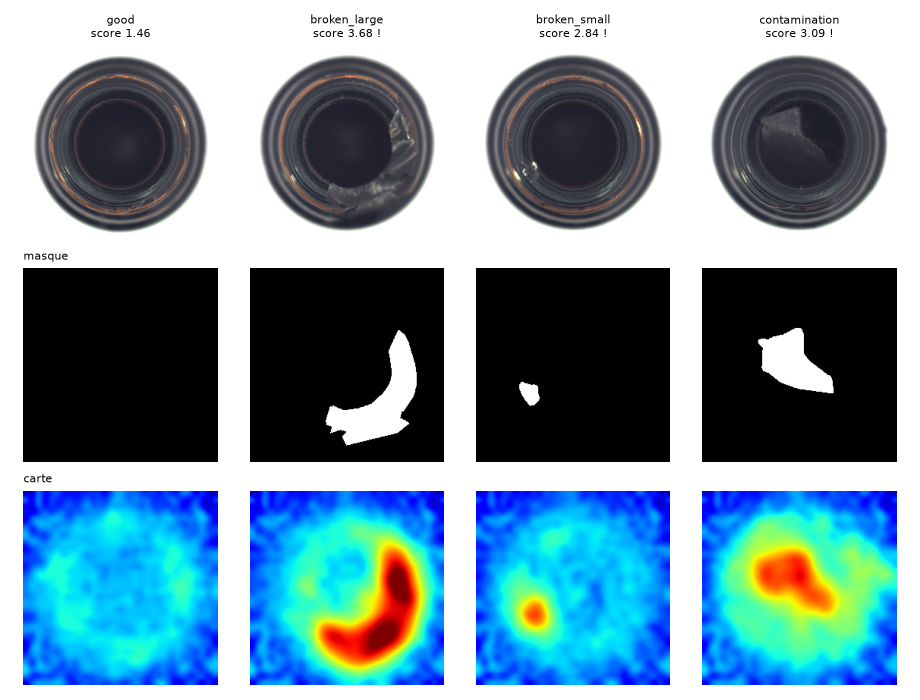

In [5]:
metrics = workflow.evaluate(config, output, device)  # mesures sur le jeu de test (AUROC, rappel, fausses alarmes...)
print({k: (round(v, 3) if isinstance(v, float) else v) for k, v in metrics.items()})  # nombres arrondis a 3 decimales
display(Image(str(output / "scores.png")))  # histogramme des scores : normales contre defauts, avec le seuil
display(Image(str(output / "maps.png")))  # exemples de cartes d'anomalie (ou le modele voit l'ecart)

## 4. Le banc de comparaison

Chaque ligne est une configuration de `recipes/anomaly/configs/` lancee par
`python recipes/anomaly/scripts/run.py --config ...` ; memes donnees, meme decoupage, meme seuil.

In [6]:
import importlib.util  # importlib.util : charge un fichier .py par son chemin (le script n'est pas un module installe)

spec = importlib.util.spec_from_file_location("benchmark", "recipes/anomaly/scripts/benchmark.py")  # decrit le module a charger
benchmark = importlib.util.module_from_spec(spec)  # cree un module vide a partir de cette description
spec.loader.exec_module(benchmark)  # execute le fichier : ses fonctions (dont collect) deviennent disponibles
table = benchmark.collect(Path("outputs/anomaly"))  # tableau des experiences deja lancees par les scripts
print(table.to_string(index=False) if len(table) else "aucune experience terminee pour l'instant")  # tableau, ou message si vide

               experience        methode  auroc_image  auroc_pixel  rappel_au_seuil  fausses_alarmes  construction_s  ms_par_image_torch onnx_ms
      anomalib_dfm_bottle            Dfm        1.000        0.935            1.000             0.05            30.4               142.7   111.4
    anomalib_padim_bottle          Padim        0.995        0.982            0.984             0.05            90.2               265.7  150.52
anomalib_patchcore_bottle      Patchcore        1.000        0.982            1.000             0.00           460.6               311.9  200.22
                 notebook patchcore_lite        1.000        0.982            1.000             0.00           292.6               268.4        
    patchcore_lite_bottle patchcore_lite        1.000        0.982            1.000             0.00           139.6               265.5  126.24
                    quick          Padim        0.997        0.975            0.984             0.05            24.1              

## 5. Predire comme en production, puis exporter

In [7]:
predictions = workflow.predict(  # score et decision pour chaque image d'un dossier ; renvoie un tableau
    config,  # la configuration de l'experience
    output,  # dossier ou se trouve le modele entraine
    device,  # CPU ou GPU
    Path(config.data.root) / "test" / "contamination",  # dossier des images a analyser (bouteilles contaminees)
    save_maps=output / "maps_contamination",  # ecrit aussi chaque image avec sa carte d'anomalie posee dessus
)
print(predictions.to_string(index=False))  # affiche le tableau des predictions
maps = sorted((output / "maps_contamination").glob("*.png"))[:4]  # les 4 premieres images superposees ecrites
fig, axes = plt.subplots(1, len(maps), figsize=(3 * len(maps), 3))  # une ligne de cases, une par image
for ax, path in zip(np.atleast_1d(axes), maps):  # pour chaque case et image (atleast_1d : marche aussi avec une seule case)
    ax.imshow(read_image(path))  # affiche l'image avec sa carte
    ax.axis("off")  # masque les axes gradues
plt.tight_layout()  # resserre les cases
plt.show()  # affiche la figure

2026-11-05 19:40:12,148 | INFO | 21 images | 21 signalees (seuil 1.91532)


                                            path    score  anomaly
data/raw/mvtec_bottle/test/contamination/000.png 3.087561     True
data/raw/mvtec_bottle/test/contamination/001.png 2.556574     True
data/raw/mvtec_bottle/test/contamination/002.png 3.472733     True
data/raw/mvtec_bottle/test/contamination/003.png 2.123410     True
data/raw/mvtec_bottle/test/contamination/004.png 2.446447     True
data/raw/mvtec_bottle/test/contamination/005.png 3.742854     True
data/raw/mvtec_bottle/test/contamination/006.png 3.129850     True
data/raw/mvtec_bottle/test/contamination/007.png 4.521575     True
data/raw/mvtec_bottle/test/contamination/008.png 3.400535     True
data/raw/mvtec_bottle/test/contamination/009.png 3.561278     True
data/raw/mvtec_bottle/test/contamination/010.png 3.658372     True
data/raw/mvtec_bottle/test/contamination/011.png 2.811410     True
data/raw/mvtec_bottle/test/contamination/012.png 2.333341     True
data/raw/mvtec_bottle/test/contamination/013.png 4.569991     

In [8]:
card = workflow.export(config, output)  # export ONNX verifie contre PyTorch ; renvoie la carte du modele (model_card.json)
# affiche une partie de la carte : entree attendue, sorties, seuils, latences, mesures (indent=1 : JSON indente)
print(json.dumps(card.model_dump(include={"input", "outputs", "thresholds", "latency_ms", "metrics"}), indent=1))

[torch.onnx] Obtain model graph for `AnomalyModel([...]` with `torch.export.export(..., strict=False)`...


[torch.onnx] Obtain model graph for `AnomalyModel([...]` with `torch.export.export(..., strict=False)`... ✅
[torch.onnx] Run decompositions...


[torch.onnx] Run decompositions... ✅
[torch.onnx] Translate the graph into ONNX...
[torch.onnx] Translate the graph into ONNX... ✅
[torch.onnx] Optimize the ONNX graph...


2026-11-05 19:40:16,516 | INFO | ONNX ecrit : outputs/anomaly/notebook/model.onnx (16.8 Mo)


[torch.onnx] Optimize the ONNX graph... ✅


2026-11-05 19:40:17,337 | INFO | verification ONNX OK : {'output_0_max_abs_diff': '1.18e-04', 'output_0_scale': '1.64e+00', 'output_1_max_abs_diff': '2.62e-06', 'output_1_scale': '1.64e+00', 'batch_size': 3}


2026-11-05 19:40:26,850 | INFO | latence : {'torch_cpu_ms': 299.83, 'batch': 1, 'onnxruntime_cpu_ms': 128.29}


{
 "input": {
  "name": "input",
  "layout": "NCHW",
  "height": 256,
  "width": 256,
  "channels": 3,
  "color": "RGB",
  "dtype": "float32",
  "scale": "divide by 255 (8 bits) or 65535 (16 bits)",
  "mean": [],
  "std": [],
  "resize": "stretch",
  "letterbox_pad_value": null,
  "dynamic_batch": true,
  "read_color": "rgb"
 },
 "outputs": [
  {
   "name": "anomaly_map",
   "shape": [
    "batch",
    1,
    256,
    256
   ],
   "description": "carte d'anomalie lissee (plus haut = plus anormal)"
  },
  {
   "name": "score",
   "shape": [
    "batch"
   ],
   "description": "score image ; anomalie si score > thresholds.image"
  }
 ],
 "thresholds": {
  "image": 1.9153181314468384,
  "pixel": 1.53969144821167
 },
 "metrics": {
  "auroc_image": 1.0,
  "auroc_pixel": 0.9821086280105968,
  "recall": 1.0,
  "false_alarm_rate": 0.0,
  "f1": 1.0,
  "n_images": 83
 },
 "latency_ms": {
  "torch_cpu_ms": 299.83,
  "onnxruntime_cpu_ms": 128.29
 }
}
